In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import unicodedata
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import statsmodels.api as sm

file_url = "https://raw.githubusercontent.com/N1tr0Lucas/Trabalho-Big-Data-em-Python/refs/heads/main/data/25-26_SG_INFLU.xlsx"

df = pd.read_excel(file_url, sheet_name="25-26_Influ")

print("Linhas: ", df.shape[0])
print("Colunas: ", df.shape[1])


df.head()

Linhas:  280262
Colunas:  25


,tp_sexo_paciente,no_raca_cor_paciente,co_municipio_paciente,no_municipio_paciente,no_pais_paciente,sg_uf_paciente,nu_cep_paciente,co_cnes_estabelecimento,no_razao_social_estabelecimento,co_municipio_estabelecimento,...,co_dose_vacina,ds_tipo_dose,ds_vacina_fabricante,co_vacina_grupo_atendimento,no_grupo_atendimento,co_categoria,ds_categoria,co_vacina_fabricante,ds_nome,nu_idade_paciente
0,F,PARDA,330490.0,SAO GONCALO,BRASIL,RJ,24474.0,2297205,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,152.0,"vacina influenza trivalente (fragmentada, inat...",11
1,F,SEM INFORMACAO,330490.0,SAO GONCALO,BRASIL,RJ,24435.0,2291908,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,NaN,"vacina influenza trivalente (fragmentada, inat...",59
2,F,PARDA,330490.0,SAO GONCALO,BRASIL,RJ,24455.0,2291762,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,152.0,"vacina influenza trivalente (fragmentada, inat...",19
3,F,PARDA,330490.0,SAO GONCALO,BRASIL,RJ,24715.0,2702959,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,152.0,"vacina influenza trivalente (fragmentada, inat...",25
4,F,SEM INFORMACAO,330490.0,SAO GONCALO,BRASIL,RJ,24722.0,2708108,PREFEITURA MUNICIPAL DE BARREIRINHA,130050,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,NaN,"vacina influenza trivalente (fragmentada, inat...",27


In [50]:

print("Resumo dos dados:")
print(df.info())
print("\nValores unicos por coluna: ")
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

Resumo dos dados:
<class 'pandas.DataFrame'>
RangeIndex: 280262 entries, 0 to 280261
Data columns (total 25 columns):
 #   Column                           Non-Null Count   Dtype         
---  ------                           --------------   -----         
 0   tp_sexo_paciente                 280262 non-null  str           
 1   no_raca_cor_paciente             280262 non-null  str           
 2   co_municipio_paciente            280067 non-null  float64       
 3   no_municipio_paciente            280067 non-null  str           
 4   no_pais_paciente                 280067 non-null  str           
 5   sg_uf_paciente                   280065 non-null  str           
 6   nu_cep_paciente                  267474 non-null  float64       
 7   co_cnes_estabelecimento          280262 non-null  int64         
 8   no_razao_social_estabelecimento  280262 non-null  str           
 9   co_municipio_estabelecimento     280262 non-null  int64         
 10  no_municipio_estabelecimento     2802

In [51]:
for coluna in df.columns:
  print(coluna)

tp_sexo_paciente
no_raca_cor_paciente
co_municipio_paciente
no_municipio_paciente
no_pais_paciente
sg_uf_paciente
nu_cep_paciente
co_cnes_estabelecimento
no_razao_social_estabelecimento
co_municipio_estabelecimento
no_municipio_estabelecimento
sg_uf_estabelecimento
co_troca_documento
sg_imunobiologico
dt_vacina
co_dose_vacina
ds_tipo_dose
ds_vacina_fabricante
co_vacina_grupo_atendimento
no_grupo_atendimento
co_categoria
ds_categoria
co_vacina_fabricante
ds_nome
nu_idade_paciente


In [52]:
df.columns = ["Sexo", "Raca", "Municipio_Codigo", "Municipio", "Pais", "UF_Paciente", "CEP_Paciente", "CNES_Estabelecimento", "Estabelecimento", "Codigo_Municipio_Estabelecimento", "Nome_Municipio_Estabelecimento", "UF_Estabelecimento", "Troca_Documento", "Sigla_Imunobiologico", "Data_Vacina", "Codigo_Vacina", "Tipo_Dose", "Fabricante_Vacina", "Codigo_Grupo_Atendimento", "Nome_Grupo_Atendimento", "Codigo_Categoria", "DS_Categoria", "Codigo_Fabricante", "Nome_Dose", "Idade"]

df.head(10)

,Sexo,Raca,Municipio_Codigo,Municipio,Pais,UF_Paciente,CEP_Paciente,CNES_Estabelecimento,Estabelecimento,Codigo_Municipio_Estabelecimento,...,Codigo_Vacina,Tipo_Dose,Fabricante_Vacina,Codigo_Grupo_Atendimento,Nome_Grupo_Atendimento,Codigo_Categoria,DS_Categoria,Codigo_Fabricante,Nome_Dose,Idade
0,F,PARDA,330490.0,SAO GONCALO,BRASIL,RJ,24474.0,2297205,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,152.0,"vacina influenza trivalente (fragmentada, inat...",11
1,F,SEM INFORMACAO,330490.0,SAO GONCALO,BRASIL,RJ,24435.0,2291908,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,NaN,"vacina influenza trivalente (fragmentada, inat...",59
2,F,PARDA,330490.0,SAO GONCALO,BRASIL,RJ,24455.0,2291762,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,152.0,"vacina influenza trivalente (fragmentada, inat...",19
3,F,PARDA,330490.0,SAO GONCALO,BRASIL,RJ,24715.0,2702959,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,152.0,"vacina influenza trivalente (fragmentada, inat...",25
4,F,SEM INFORMACAO,330490.0,SAO GONCALO,BRASIL,RJ,24722.0,2708108,PREFEITURA MUNICIPAL DE BARREIRINHA,130050,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,NaN,"vacina influenza trivalente (fragmentada, inat...",27
5,M,BRANCA,330490.0,SAO GONCALO,BRASIL,RJ,24737.0,2297213,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,152.0,"vacina influenza trivalente (fragmentada, inat...",1
6,F,SEM INFORMACAO,330490.0,SAO GONCALO,BRASIL,RJ,24473.0,2291983,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,152.0,"vacina influenza trivalente (fragmentada, inat...",8
7,F,AMARELA,330490.0,SAO GONCALO,BRASIL,RJ,24753.0,2702959,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,152.0,"vacina influenza trivalente (fragmentada, inat...",56
8,F,SEM INFORMACAO,330490.0,SAO GONCALO,BRASIL,RJ,24456.0,2291819,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,330490,...,9,Única,INSTITUTO BUTANTAN,NaN,NaN,NaN,NaN,NaN,"vacina influenza trivalente (fragmentada, inat...",39
9,M,PARDA,330490.0,SAO GONCALO,BRASIL,RJ,24716.0,12637,FUNDACAO MUNICIPAL DE SAUDE DE NITEROI,330330,...,9,Única,BUTANTAN,210.0,Faixa Etária,2.0,Faixa Etária,152.0,"vacina influenza trivalente (fragmentada, inat...",2


In [53]:
df.describe(include="all")

,Sexo,Raca,Municipio_Codigo,Municipio,Pais,UF_Paciente,CEP_Paciente,CNES_Estabelecimento,Estabelecimento,Codigo_Municipio_Estabelecimento,...,Codigo_Vacina,Tipo_Dose,Fabricante_Vacina,Codigo_Grupo_Atendimento,Nome_Grupo_Atendimento,Codigo_Categoria,DS_Categoria,Codigo_Fabricante,Nome_Dose,Idade
count,280262,280262,280067.000000,280067,280067,280065,2.674740e+05,2.802620e+05,280262,280262.000000,...,280262.000000,280262,278610,257025.000000,256693,256693.000000,256693,2.553550e+05,280262,280262.000000
unique,3,6,NaN,442,1,24,NaN,NaN,1828,NaN,...,NaN,6,147,NaN,86,NaN,23,NaN,2,NaN
top,F,SEM INFORMACAO,NaN,SAO GONCALO,BRASIL,RJ,NaN,NaN,SECRETARIA MUNICIPAL DE SAUDE DE SAO GONCALO,NaN,...,NaN,Única,FUNDACAO BUTANTAN,NaN,Faixa Etária,NaN,Faixa Etária,NaN,"vacina influenza trivalente (fragmentada, inat...",NaN
freq,168565,150742,NaN,274372,280067,279340,NaN,NaN,221443,NaN,...,NaN,268087,249683,NaN,232542,NaN,232542,NaN,276735,NaN
mean,NaN,NaN,330444.302424,NaN,NaN,NaN,5.495549e+06,3.447493e+06,NaN,330477.391170,...,8.690739,NaN,NaN,363.496660,NaN,2.659574,NaN,2.073314e+08,NaN,42.164368
min,NaN,NaN,110002.000000,NaN,NaN,NaN,0.000000e+00,4.300000e+01,NaN,110004.000000,...,1.000000,NaN,NaN,0.000000,NaN,1.000000,NaN,1.420000e+02,NaN,0.000000
25%,NaN,NaN,330490.000000,NaN,NaN,NaN,2.445100e+04,2.291703e+06,NaN,330490.000000,...,9.000000,NaN,NaN,210.000000,NaN,2.000000,NaN,1.520000e+02,NaN,17.000000
50%,NaN,NaN,330490.000000,NaN,NaN,NaN,2.472000e+04,2.297213e+06,NaN,330490.000000,...,9.000000,NaN,NaN,210.000000,NaN,2.000000,NaN,1.520000e+02,NaN,45.000000
75%,NaN,NaN,330490.000000,NaN,NaN,NaN,2.475300e+04,4.065417e+06,NaN,330490.000000,...,9.000000,NaN,NaN,210.000000,NaN,2.000000,NaN,1.520000e+02,NaN,65.000000
max,NaN,NaN,999999.000000,NaN,NaN,NaN,1.000000e+08,9.996478e+06,NaN,530010.000000,...,38.000000,NaN,NaN,999999.000000,NaN,602.000000,NaN,1.058860e+13,NaN,126.000000


In [54]:
df.isnull().sum()

Sexo                                     0
Raca                                     0
Municipio_Codigo                       195
Municipio                              195
Pais                                   195
UF_Paciente                            197
CEP_Paciente                         12788
CNES_Estabelecimento                     0
Estabelecimento                          0
Codigo_Municipio_Estabelecimento         0
Nome_Municipio_Estabelecimento           0
UF_Estabelecimento                       0
Troca_Documento                     279657
Sigla_Imunobiologico                     0
Data_Vacina                          44742
Codigo_Vacina                            0
Tipo_Dose                                0
Fabricante_Vacina                     1652
Codigo_Grupo_Atendimento             23237
Nome_Grupo_Atendimento               23569
Codigo_Categoria                     23569
DS_Categoria                         23569
Codigo_Fabricante                    24907
Nome_Dose  

In [55]:
df.duplicated().sum()

np.int64(4131)

In [56]:
df.columns = df.columns.str.strip()

df.duplicated().sum()

df = df.drop_duplicates()

df.isnull().sum().sort_values(ascending=False)

Troca_Documento                     275546
Data_Vacina                          44120
Codigo_Fabricante                    24846
Codigo_Categoria                     23516
Nome_Grupo_Atendimento               23516
DS_Categoria                         23516
Codigo_Grupo_Atendimento             23186
CEP_Paciente                         12491
Fabricante_Vacina                     1644
UF_Paciente                            194
Municipio                              192
Pais                                   192
Municipio_Codigo                       192
Estabelecimento                          0
CNES_Estabelecimento                     0
Raca                                     0
Sexo                                     0
Tipo_Dose                                0
Codigo_Vacina                            0
Sigla_Imunobiologico                     0
UF_Estabelecimento                       0
Codigo_Municipio_Estabelecimento         0
Nome_Municipio_Estabelecimento           0
Nome_Dose  

In [57]:
colunas_interesse = ['Sexo', 'Municipio', 'Idade', 'Nome_Dose', 'Data_Vacina']

df_filtrado = df[colunas_interesse]

df_filtrado.head()

,Sexo,Municipio,Idade,Nome_Dose,Data_Vacina
0,F,SAO GONCALO,11,"vacina influenza trivalente (fragmentada, inat...",2025-01-16
1,F,SAO GONCALO,59,"vacina influenza trivalente (fragmentada, inat...",2025-01-08
2,F,SAO GONCALO,19,"vacina influenza trivalente (fragmentada, inat...",2025-01-12
3,F,SAO GONCALO,25,"vacina influenza trivalente (fragmentada, inat...",2025-01-06
4,F,SAO GONCALO,27,"vacina influenza trivalente (fragmentada, inat...",2025-01-10


In [58]:
df['Nome_Dose'].unique()

<StringArray>
['vacina influenza trivalente (fragmentada, inativada)', 'vacina influenza tetravalente (fragmentada, inativada)']
Length: 2, dtype: str

In [59]:
df['Nome_Dose'].value_counts()

Nome_Dose
vacina influenza trivalente (fragmentada, inativada)      272628
vacina influenza tetravalente (fragmentada, inativada)      3503
Name: count, dtype: int64

Fabricante_Vacina
Instituto Butantan    271123
Nao informado           2299
Abbott                  1403
Sanofi                  1097
GlaxoSmithKline          111
Outros                    44
Fiocruz                   35
Instituto Serum           19
Name: count, dtype: int64


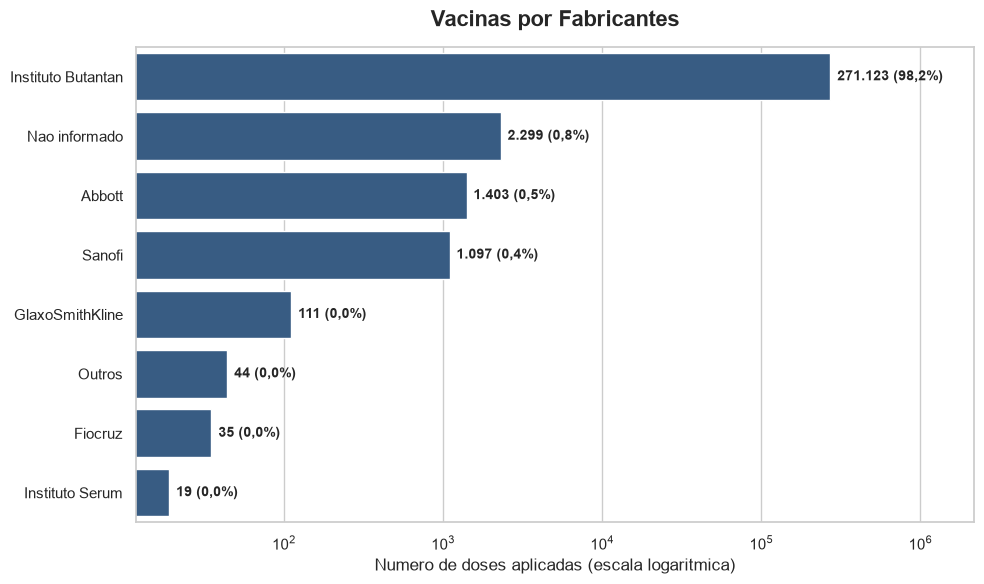

In [60]:
def padronizar_fabricante(valor):
    if pd.isna(valor):
        return 'Nao informado'
    s = unicodedata.normalize('NFKD', valor).encode('ASCII', 'ignore').decode('utf-8').upper()
    s = re.sub(r'[^A-Z0]', '', s)

    if s == '' or re.search(r'PENDENTE|NAOINFORMADO|REGISTRODECART|^INFLUENZA$', s):
        return 'Nao informado'
    if re.search(r'SERUM|SRUM', s):
        return 'Instituto Serum'
    if re.search(r'SANOFI', s):
        return 'Sanofi'
    if re.search(r'ABBOTT', s):
        return 'Abbott'
    if re.search(r'GLAXO', s):
        return 'GlaxoSmithKline'
    if re.search(r'BUT|BUN|BUA|BUB|BTT|ANTAN|INSTITUTO|INSTITUTE|INTITUTO|INSTUTO|INSITUTO|INTISTUTO|FUNDACAO|FUNDAO|^IB$|^INST', s):
        return 'Instituto Butantan'
    if re.search(r'FIO|OSWALDO|MANGUINHOS', s):
        return 'Fiocruz'
    return 'Outros'

df['Fabricante_Vacina'] = df['Fabricante_Vacina'].apply(padronizar_fabricante)

contagem = df['Fabricante_Vacina'].value_counts()
print(contagem)

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=contagem.values, y=contagem.index, ax=ax, color='#2b5c8f')
ax.set_xscale('log')

total = contagem.sum()
for p, v in zip(ax.patches, contagem.values):
    texto = f'{v:,} ({v / total * 100:.1f}%)'
    texto = texto.replace(',', 'X').replace('.', ',').replace('X', '.')   
    ax.annotate(texto, (p.get_width(), p.get_y() + p.get_height() / 2),
                xytext=(5, 0), textcoords='offset points',
                va='center', fontsize=10, fontweight='bold')


ax.set_xlim(right=contagem.max() * 8)

ax.set_title('Vacinas por Fabricantes', fontsize=16, fontweight='bold', pad=15)

ax.set_xlabel('Numero de doses aplicadas (escala logaritmica)', fontsize=12)

ax.set_ylabel('')

plt.tight_layout()

plt.savefig('vacinas_por_fabricantes.png', dpi=300)

plt.show()


In [61]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
Index: 276131 entries, 0 to 280261
Data columns (total 25 columns):
 #   Column                            Non-Null Count   Dtype         
---  ------                            --------------   -----         
 0   Sexo                              276131 non-null  str           
 1   Raca                              276131 non-null  str           
 2   Municipio_Codigo                  275939 non-null  float64       
 3   Municipio                         275939 non-null  str           
 4   Pais                              275939 non-null  str           
 5   UF_Paciente                       275937 non-null  str           
 6   CEP_Paciente                      263640 non-null  float64       
 7   CNES_Estabelecimento              276131 non-null  int64         
 8   Estabelecimento                   276131 non-null  str           
 9   Codigo_Municipio_Estabelecimento  276131 non-null  int64         
 10  Nome_Municipio_Estabelecimento    276131 non-nul

In [62]:
print("\nData range for dt_vacina:")
df['Data_Vacina'] = pd.to_datetime(df['Data_Vacina'], errors='coerce')
print(df['Data_Vacina'].min(), "to", df['Data_Vacina'].max())

# Group by date to get daily vaccination count
daily_vac = df.groupby(df['Data_Vacina'].dt.date).size().reset_index(name='total_vacinas')
print("\nDaily vaccinations summary:")
print(daily_vac.describe())
print(daily_vac.head(100))



Data range for dt_vacina:
2025-01-02 00:00:00 to 2026-12-09 00:00:00

Daily vaccinations summary:
       total_vacinas
count      323.00000
mean       718.30031
std       1289.64556
min          1.00000
25%         14.00000
50%        191.00000
75%        764.00000
max      14266.00000
   Data_Vacina  total_vacinas
0   2025-01-02             70
1   2025-01-03             78
2   2025-01-04              5
3   2025-01-05              5
4   2025-01-06            152
..         ...            ...
95  2025-04-21             12
96  2025-04-22             91
97  2025-04-23            100
98  2025-04-24           1749
99  2025-04-25           2054

[100 rows x 2 columns]


In [63]:
#df[df['Fabricante_Vacina'].str.contains('FIOCRUZ')]

#df[df['Fabricante_Vacina'].str.len() > 20]

#df[df['Fabricante_Vacina'].isin(['BUTANTAN'])]

#df.loc[[1]]

#df[df['Idade'] <90]

#df[df['Data_Vacina'].dt.month == 6]

In [64]:
df['Idade'] = df['Idade'].astype(int, errors='ignore')
print("\n---Resumo Idade---")
print(df['Idade'].describe())


---Resumo Idade---
count    276131.000000
mean         42.220660
std          26.181224
min           0.000000
25%          17.000000
50%          45.000000
75%          65.000000
max         126.000000
Name: Idade, dtype: float64


In [65]:
df['Sexo'] = df['Sexo'].astype(str)
print("\n---Distribuicao por Sexo---")
print(df['Sexo'].value_counts(normalize=True)*100)


---Distribuicao por Sexo---
Sexo
F    60.155144
M    39.840873
I     0.003984
Name: proportion, dtype: float64


In [66]:
print("\n---Distribuicao por Dose---:")
print(df['Nome_Dose'].value_counts(normalize=True)*100)


---Distribuicao por Dose---:
Nome_Dose
vacina influenza trivalente (fragmentada, inativada)      98.731399
vacina influenza tetravalente (fragmentada, inativada)     1.268601
Name: proportion, dtype: float64


Sexo
F    166107
M    110013
I        11
Name: count, dtype: int64


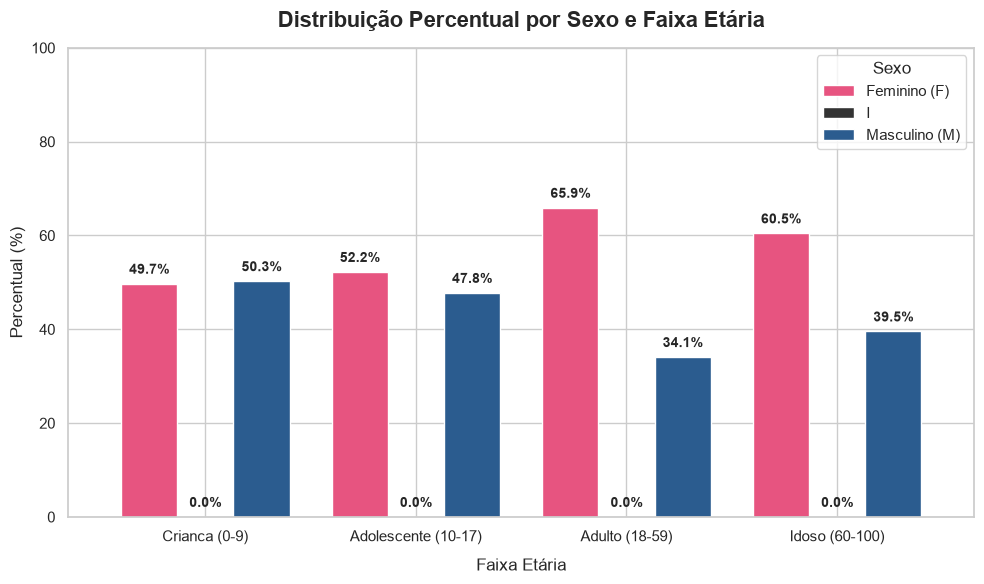

In [67]:
bins = [0, 10, 18, 60, 100]

labels = ['Crianca (0-9)', 'Adolescente (10-17)', 'Adulto (18-59)', 'Idoso (60-100)']
df['Faixa_Etaria'] = pd.cut(df['Idade'], bins=bins, labels=labels, right=False)

df['Sexo'] = df['Sexo'].astype(str).str.strip().str.upper().str[0]
print(df['Sexo'].value_counts(dropna=False))

tabela_cruzada = pd.crosstab(df['Faixa_Etaria'], df['Sexo'], normalize='index') * 100

cores = {'F': '#e75480', 'M': '#2b5c8f'}
nomes = {'F': 'Feminino (F)', 'M': 'Masculino (M)'}

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

tabela_cruzada.plot(
    kind='bar', ax=ax, width=0.8, color=[cores.get(c, '#333333') for c in tabela_cruzada.columns]
)

ax.set_title('Distribuição Percentual por Sexo e Faixa Etária', fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Faixa Etária', fontsize=12, labelpad=10)
ax.set_ylabel('Percentual (%)', fontsize=12)
ax.set_ylim(0, 100)
ax.tick_params(axis='x', rotation=0, labelsize=11)
ax.legend([nomes.get(c,c) for c in tabela_cruzada.columns], title='Sexo', frameon=True, facecolor='white')   

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f'{h:.1f}%', (p.get_x() + p.get_width() / 2, h + 1.5),
                    ha='center', va='bottom', fontsize=10, fontweight='bold')
        
plt.tight_layout()

plt.savefig('distribuicao_sexo_faixa_etaria.png', dpi=300)

plt.show()           
        
#print("\n---Perfil por Faixa Etaria e Sexo---")
#print(tabela_cruzada)

Intercepto: 4159.95
Coeficiente (Idade): -29.95
R²: 0.410
                            OLS Regression Results                            
Dep. Variable:              Vacinados   R-squared:                       0.410
Model:                            OLS   Adj. R-squared:                  0.404
Method:                 Least Squares   F-statistic:                     75.03
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           5.03e-14
Time:                        15:12:24   Log-Likelihood:                -934.09
No. Observations:                 110   AIC:                             1872.
Df Residuals:                     108   BIC:                             1878.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------

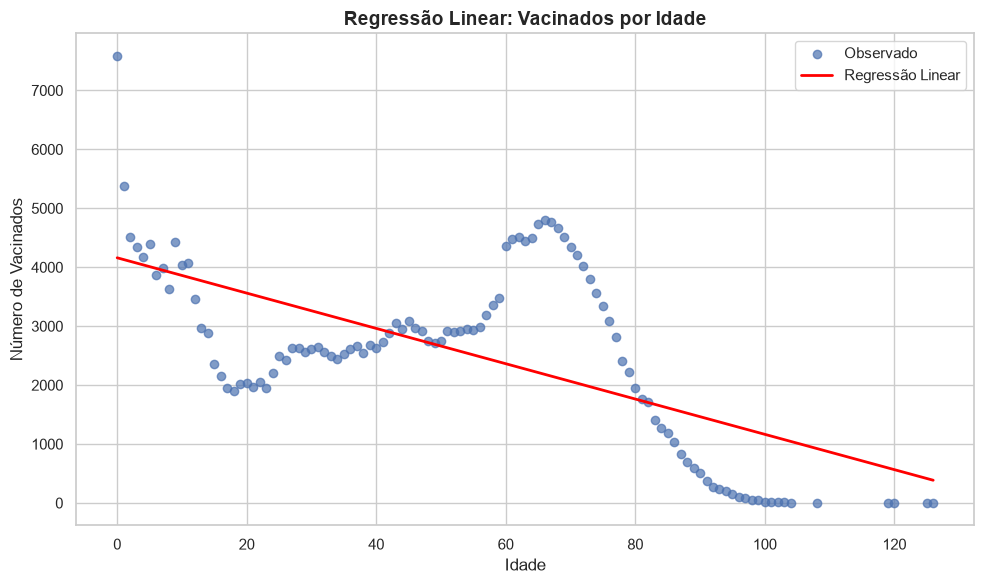

In [68]:
#REGRESSAO LINEAR 

dados = (df['Idade'] .value_counts() .sort_index() .rename_axis('Idade') .reset_index(name='Vacinados'))

x = dados[['Idade']]

y = dados['Vacinados']

#--------------------------------------------------

modelo = LinearRegression()

modelo.fit(x, y)

ypred = modelo.predict(x)

print(f"Intercepto: {modelo.intercept_:.2f}")

print(f"Coeficiente (Idade): {modelo.coef_[0]:.2f}")

print(f"R²: {r2_score(y, ypred):.3f}")

#--------------------------------------------------

X_sm = sm.add_constant(x)
ols = sm.OLS(y, X_sm).fit()
print(ols.summary())

#--------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(dados['Idade'], y, alpha=0.7, label='Observado')

ax.plot(dados['Idade'], ypred, color='red', linewidth=2, label='Regressão Linear')

ax.set_title('Regressão Linear: Vacinados por Idade', fontsize=14, fontweight='bold')

ax.set_xlabel('Idade')

ax.set_ylabel('Número de Vacinados')

ax.legend()

plt.tight_layout()

plt.savefig('regressao_linear_vacinados_idade.png', dpi=300)

plt.show()